# SCAMPER Gait Trail Renders

Load saved SCAMPER walk, trot, and canter rollouts and render interactive trail visualizations.

In [1]:
%load_ext autoreload
%autoreload 2

import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["PYOPENGL_PLATFORM"] = "egl"
os.environ["MUJOCO_GL"] = "egl"

import io
from pathlib import Path
from types import SimpleNamespace

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import mediapy as media
import mujoco
import numpy as np
import PIL.Image
from PIL import ImageDraw, ImageFont
import ipywidgets as widgets
from IPython.display import display as ipy_display

from brax.training import distribution
from brax.training.acme import running_statistics, specs
from brax.training.agents.ppo import networks as ppo_networks

from scamper.environment.rodent import consts as rodent_consts
from scamper.environment.rodent import maintain_velocity

from scamper.agent.task_transfer.maintain_velocity.checkpoint_utils import (
    load_prior_checkpoint,
    load_task_transfer_metadata,
    load_task_transfer_brax_params,
    make_decoder_inference_fn,
    make_prior_inference_fn,
)
from scamper.agent.task_transfer.maintain_velocity.wrappers import (
    DecoderHighLevelWrapper,
    FlatObsWrapper,
    PriorDecoderHighLevelWrapper,
)
from scamper.agent.task_transfer.maintain_velocity.scratch_networks import (
    make_scratch_ppo_networks,
)


In [12]:
# ============================================================
# Configuration for all three gaits
# ============================================================

GAITS = [
    {
        "name": "SCAMPER_S3e-1",
        "label": "Walk",
        "checkpoint_path": "/home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260403_015403_017303",
        "checkpoint_step": 25,
        "seed": 0,
    },
    {
        "name": "SCAMPER_S5e-1",
        "label": "Trot",
        "checkpoint_path": "/home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260403_054936_177691",
        "checkpoint_step": 24,
        "seed": 0,
    },
    {
        "name": "SCAMPER_S7e-1",
        "label": "Canter",
        "checkpoint_path": "/home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260403_054936_245874",
        "checkpoint_step": 23,
        "seed": 0,
    },
]

DATA_BASE_DIR = Path("/home/mila/a/aidan.sirbu/SCAMPER/data/final_maintain_velocity_analysis")
OUTPUT_DIR = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/maintain_velocity_trails")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Rendering
RENDER_CAMERA = "close_profile-rodent"
RENDER_HEIGHT = 1080
RENDER_WIDTH = 1248
RENDER_FPS = 50

# Trail settings (shared across gaits, override per-gait below if needed)
TRAIL_NUM_FRAMES = 5
TRAIL_T_START = 0
TRAIL_T_END = 300
TRAIL_TIMESTEPS_OVERRIDE = []  # e.g. [0, 111, 150, 222, 400]; empty = linspace


TRAIL_CAM_POS = [-0.7, 0.1, 0.25]
TRAIL_CAM_LOOKAT = [0.0, 0.425, 0.0]
TRAIL_CAM_FOVY = 45

TRAIL_RENDER_HEIGHT = 1080
TRAIL_RENDER_WIDTH = 2048


## Load Rollouts and Build Models

In [4]:
# Load each rollout from npz and build the single-rodent MuJoCo model
gait_data = {}

for gait_cfg in GAITS:
    name = gait_cfg["name"]
    label = gait_cfg["label"]
    ckpt_path = gait_cfg["checkpoint_path"]
    ckpt_step = gait_cfg["checkpoint_step"]
    seed = gait_cfg["seed"]
    run_id = Path(ckpt_path).name

    print(f"\n{'='*60}")
    print(f"Loading: {label} ({name})")
    print(f"{'='*60}")

    # Load checkpoint metadata (needed for env config)
    ckpt_info = load_task_transfer_metadata(ckpt_path, step=ckpt_step)
    config = ckpt_info["config"]
    ckpt_cfg = config["checkpoint_config"]
    ckpt_step_actual = ckpt_info["step"]

    # Load rollout
    save_path = DATA_BASE_DIR / name / f"rollout_{name}_step{ckpt_step_actual}_seed{seed}_{run_id}.npz"
    print(f"  Loading rollout from {save_path}")
    loaded = np.load(save_path)
    qpos = loaded["qpos"]
    print(f"  qpos shape: {qpos.shape}")

    # Build single-rodent model for computing torso positions and rendering
    xml_variant = config["env"].get("xml_variant", "full-collisions")
    if xml_variant == "limited-collisions":
        walker_xml = str(rodent_consts.RODENT_XML_PATH)
    elif xml_variant == "full-collisions":
        walker_xml = str(rodent_consts.RODENT_FULL_COLLISION_XML)
    elif xml_variant == "no-tail-collisions":
        walker_xml = str(rodent_consts.RODENT_NO_TAIL_COLLISION_XML)
    else:
        raise ValueError(f"Unknown xml_variant: {xml_variant}")

    arena_xml = str(rodent_consts.ARENA_XML_PATH)

    arena_spec = mujoco.MjSpec.from_file(arena_xml)
    rodent_spec = mujoco.MjSpec.from_file(walker_xml)
    frame = arena_spec.worldbody.add_frame(pos=(0, 0, 0), quat=(1, 0, 0, 0))
    spawn_body = frame.attach_body(rodent_spec.body("walker"), "", suffix="-rodent")
    spawn_body.add_freejoint(name="root")

    light = arena_spec.worldbody.add_light(name="overhead")
    light.pos = [0, 0, 10]
    light.dir = [0, 0, -1]
    light.type = mujoco.mjtLightType.mjLIGHT_DIRECTIONAL
    light.diffuse = [1.0, 1.0, 1.0]
    light.specular = [0.3, 0.3, 0.3]

    model = arena_spec.compile()
    data = mujoco.MjData(model)

    print(f"  Model nq: {model.nq}, walker_xml: {xml_variant}")
    assert model.nq == qpos.shape[1]

    gait_data[label] = {
        "qpos": qpos,
        "model": model,
        "data": data,
        "walker_xml": walker_xml,
        "arena_xml": arena_xml,
        "config": config,
        "ckpt_step": ckpt_step_actual,
        "name": name,
        "seed": seed,
        "run_id": run_id,
    }

print(f"\nLoaded {len(gait_data)} gaits: {list(gait_data.keys())}")



Loading: Walk (SCAMPER_S3e-1)
  Loading rollout from /home/mila/a/aidan.sirbu/SCAMPER/data/final_maintain_velocity_analysis/SCAMPER_S3e-1/rollout_SCAMPER_S3e-1_step25_seed0_260403_015403_017303.npz
  qpos shape: (1001, 74)
  Model nq: 74, walker_xml: no-tail-collisions

Loading: Trot (SCAMPER_S5e-1)
  Loading rollout from /home/mila/a/aidan.sirbu/SCAMPER/data/final_maintain_velocity_analysis/SCAMPER_S5e-1/rollout_SCAMPER_S5e-1_step24_seed0_260403_054936_177691.npz
  qpos shape: (1001, 74)
  Model nq: 74, walker_xml: no-tail-collisions

Loading: Canter (SCAMPER_S7e-1)
  Loading rollout from /home/mila/a/aidan.sirbu/SCAMPER/data/final_maintain_velocity_analysis/SCAMPER_S7e-1/rollout_SCAMPER_S7e-1_step23_seed0_260403_054936_245874.npz
  qpos shape: (1001, 74)
  Model nq: 74, walker_xml: no-tail-collisions

Loaded 3 gaits: ['Walk', 'Trot', 'Canter']


## Render Videos

In [ ]:
# Render standard video for each gait
for label, gd in gait_data.items():
    print(f"\nRendering {label}...")
    model = gd["model"]
    data = gd["data"]
    qpos = gd["qpos"]

    cam_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_CAMERA, RENDER_CAMERA)
    renderer = mujoco.Renderer(model, height=RENDER_HEIGHT, width=RENDER_WIDTH)

    frames = []
    for t in range(qpos.shape[0]):
        data.qpos[:] = qpos[t]
        mujoco.mj_forward(model, data)
        renderer.update_scene(data, camera=cam_id)
        frames.append(renderer.render().copy())

    renderer.close()

    print(f"  {label}: {len(frames)} frames")
    media.show_video(frames, fps=RENDER_FPS, title=label)


## Walk — Interactive Trail Render

In [10]:
# Build multi-rodent trail for Walk
# === Per-gait overrides (edit these) ===
TRAIL_T_START_WALK = 300       # override start timestep
TRAIL_T_END_WALK = 600           # override end timestep
TRAIL_NUM_FRAMES_WALK = TRAIL_NUM_FRAMES # override number of poses
TRAIL_TIMESTEPS_WALK = []                 # explicit timesteps; empty = linspace

gd = gait_data["Walk"]
qpos = gd["qpos"]
model = gd["model"]
data = gd["data"]
walker_xml = gd["walker_xml"]
arena_xml = gd["arena_xml"]

# Trail timesteps
if TRAIL_TIMESTEPS_WALK:
    trail_indices = np.array(TRAIL_TIMESTEPS_WALK, dtype=int)
else:
    trail_indices = np.linspace(TRAIL_T_START_WALK, TRAIL_T_END_WALK, TRAIL_NUM_FRAMES_WALK, dtype=int)
trail_num_frames = len(trail_indices)

# Build multi-rodent MjSpec
trail_spec = mujoco.MjSpec.from_file(arena_xml)
for i in range(trail_num_frames):
    rodent_spec_i = mujoco.MjSpec.from_file(walker_xml)
    frame_i = trail_spec.worldbody.add_frame(pos=(0, 0, 0), quat=(1, 0, 0, 0))
    body_i = frame_i.attach_body(rodent_spec_i.body("walker"), "", suffix=f"-t{i}")
    body_i.add_freejoint(name=f"root-t{i}")

# Camera
cam_pos = np.array(TRAIL_CAM_POS, dtype=float)
cam_lookat = np.array(TRAIL_CAM_LOOKAT, dtype=float)
look_dir = cam_lookat - cam_pos
cam_z = -look_dir / np.linalg.norm(look_dir)
world_up = np.array([0.0, 0.0, 1.0])
cam_x = np.cross(world_up, cam_z)
cam_x /= np.linalg.norm(cam_x)
cam_y = np.cross(cam_z, cam_x)
R = np.column_stack([cam_x, cam_y, cam_z])
trace = R[0, 0] + R[1, 1] + R[2, 2]
s = 2.0 * np.sqrt(1.0 + trace)
cam_quat = [0.25 * s, (R[2, 1] - R[1, 2]) / s, (R[0, 2] - R[2, 0]) / s, (R[1, 0] - R[0, 1]) / s]

overview_cam = trail_spec.worldbody.add_camera(name="trail_overview")
overview_cam.pos = cam_pos.tolist()
overview_cam.quat = cam_quat
overview_cam.fovy = TRAIL_CAM_FOVY

overhead = trail_spec.worldbody.add_light(name="overhead")
overhead.pos = [0.0, 0.0, 10.0]
overhead.dir = [0, 0, -1]
overhead.type = mujoco.mjtLightType.mjLIGHT_DIRECTIONAL
overhead.diffuse = [1.0, 1.0, 1.0]
overhead.specular = [0.3, 0.3, 0.3]

trail_model = trail_spec.compile()

# Disable tracking lights from rodent copies
for i in range(trail_model.nlight):
    lname = mujoco.mj_id2name(trail_model, mujoco.mjtObj.mjOBJ_LIGHT, i)
    if lname and "tracking_light" in lname:
        trail_model.light_diffuse[i] = [0, 0, 0]
        trail_model.light_specular[i] = [0, 0, 0]

trail_data = mujoco.MjData(trail_model)

# Set each copy's qpos
nq_single = model.nq
for i, t in enumerate(trail_indices):
    start = i * nq_single
    trail_data.qpos[start : start + nq_single] = qpos[t]
mujoco.mj_forward(trail_model, trail_data)

print(f"{trail_num_frames} poses at timesteps: {trail_indices.tolist()}")

# Interactive viewer
interactive_height = 1080
interactive_width = 2048

interactive_renderer = mujoco.Renderer(trail_model, height=interactive_height, width=interactive_width)
free_cam = mujoco.MjvCamera()
free_cam.type = mujoco.mjtCamera.mjCAMERA_FREE

try:
    _has_capture = bool(captured_cam_walk)
except NameError:
    captured_cam_walk = {}
    _has_capture = False

if _has_capture:
    free_cam.azimuth = captured_cam_walk["azimuth"]
    free_cam.elevation = captured_cam_walk["elevation"]
    free_cam.distance = captured_cam_walk["distance"]
    free_cam.lookat[:] = captured_cam_walk["lookat"]
else:
    free_cam.lookat[:] = TRAIL_CAM_LOOKAT
    free_cam.distance = float(np.linalg.norm(np.array(TRAIL_CAM_POS) - np.array(TRAIL_CAM_LOOKAT)))
    _offset = np.array(TRAIL_CAM_POS) - np.array(TRAIL_CAM_LOOKAT)
    free_cam.azimuth = float(np.degrees(np.arctan2(_offset[1], _offset[0])))
    free_cam.elevation = float(np.degrees(np.arcsin(_offset[2] / np.linalg.norm(_offset))))

img_widget = widgets.Image(format="jpeg", layout=widgets.Layout(width=f"{interactive_width}px"))

def render_view(change=None):
    interactive_renderer.update_scene(trail_data, camera=free_cam)
    frame = interactive_renderer.render()
    buf = io.BytesIO()
    PIL.Image.fromarray(frame).save(buf, format="JPEG", quality=90)
    img_widget.value = buf.getvalue()

azimuth_slider = widgets.FloatSlider(value=free_cam.azimuth, min=-180, max=180, step=1, description="Azimuth", continuous_update=True, layout=widgets.Layout(width="500px"))
elevation_slider = widgets.FloatSlider(value=free_cam.elevation, min=-90, max=90, step=1, description="Elevation", continuous_update=True, layout=widgets.Layout(width="500px"))
distance_slider = widgets.FloatSlider(value=free_cam.distance, min=0.1, max=5.0, step=0.05, description="Distance", continuous_update=True, layout=widgets.Layout(width="500px"))
lookat_x = widgets.FloatSlider(value=free_cam.lookat[0], min=-3, max=3, step=0.05, description="Lookat X", continuous_update=True, layout=widgets.Layout(width="500px"))
lookat_y = widgets.FloatSlider(value=free_cam.lookat[1], min=-3, max=3, step=0.05, description="Lookat Y", continuous_update=True, layout=widgets.Layout(width="500px"))
lookat_z = widgets.FloatSlider(value=free_cam.lookat[2], min=-1, max=2, step=0.05, description="Lookat Z", continuous_update=True, layout=widgets.Layout(width="500px"))

def on_slider_change(change):
    free_cam.azimuth = azimuth_slider.value
    free_cam.elevation = elevation_slider.value
    free_cam.distance = distance_slider.value
    free_cam.lookat[:] = [lookat_x.value, lookat_y.value, lookat_z.value]
    render_view()

for sl in [azimuth_slider, elevation_slider, distance_slider, lookat_x, lookat_y, lookat_z]:
    sl.observe(on_slider_change, names="value")

capture_label = widgets.Label(value="")
capture_btn = widgets.Button(description="Capture Camera", button_style="success")

def on_capture(btn):
    captured_cam_walk["azimuth"] = azimuth_slider.value
    captured_cam_walk["elevation"] = elevation_slider.value
    captured_cam_walk["distance"] = distance_slider.value
    captured_cam_walk["lookat"] = [lookat_x.value, lookat_y.value, lookat_z.value]
    capture_label.value = f"Captured: az={captured_cam_walk['azimuth']:.1f} el={captured_cam_walk['elevation']:.1f} dist={captured_cam_walk['distance']:.2f}"

capture_btn.on_click(on_capture)
render_view()

controls = widgets.VBox([
    widgets.HBox([azimuth_slider, elevation_slider]),
    widgets.HBox([distance_slider]),
    widgets.HBox([lookat_x, lookat_y, lookat_z]),
    widgets.HBox([capture_btn, capture_label]),
])
ipy_display(widgets.VBox([img_widget, controls]))


5 poses at timesteps: [300, 375, 450, 525, 600]


Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/maintain_velocity_trails/walk/trail_walk_SCAMPER_S3e-1.[pdf|svg|png]


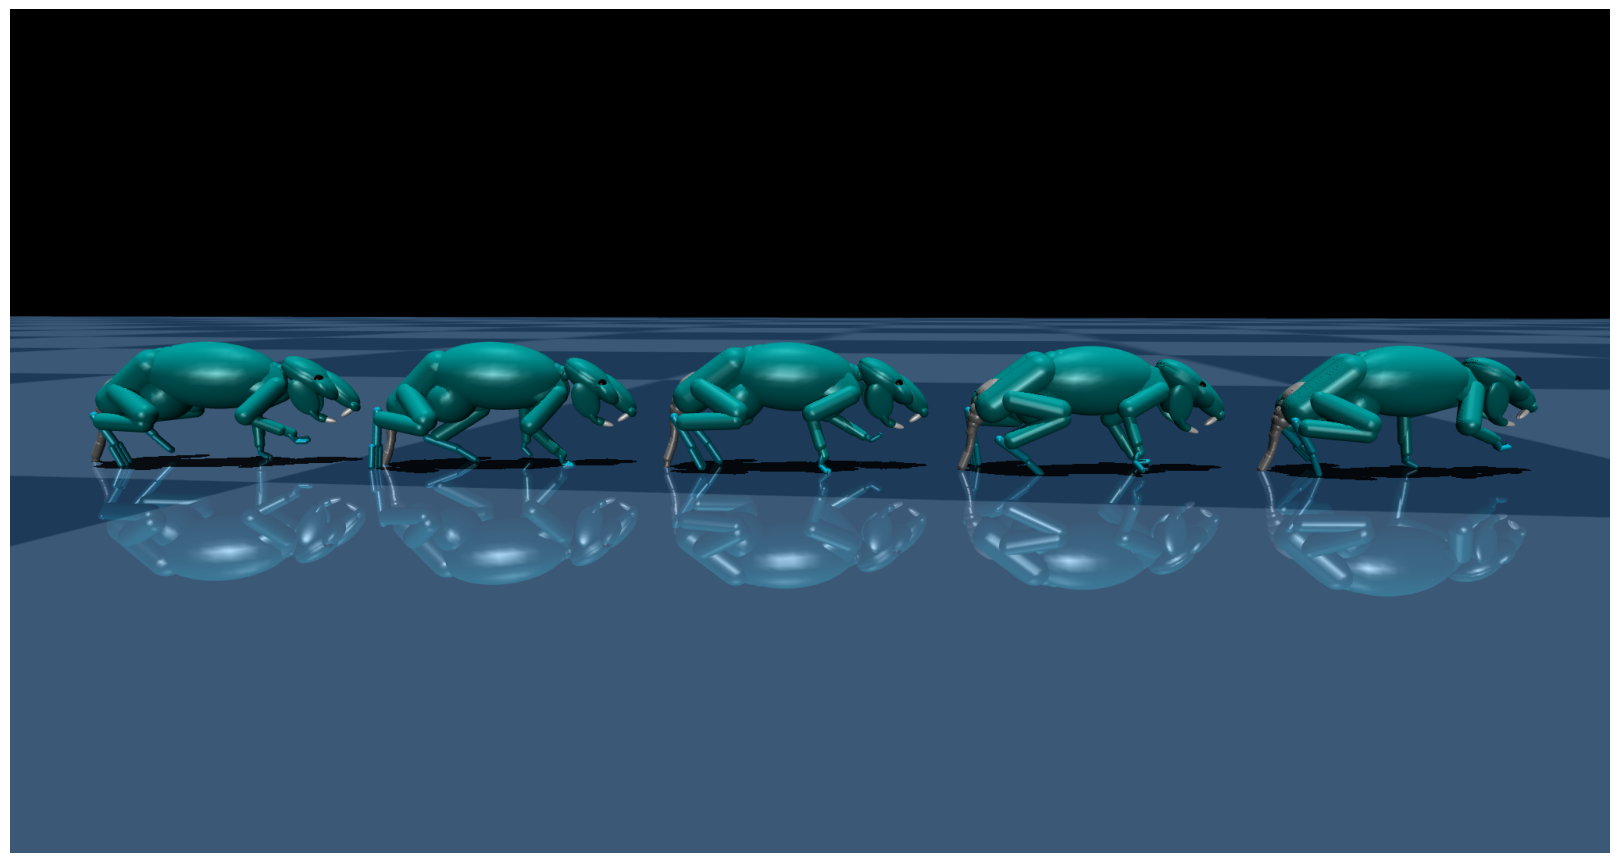

In [13]:
# High-res render for Walk
assert captured_cam_walk, "Click 'Capture Camera' above first"

hires_cam = mujoco.MjvCamera()
hires_cam.type = mujoco.mjtCamera.mjCAMERA_FREE
hires_cam.azimuth = captured_cam_walk["azimuth"]
hires_cam.elevation = captured_cam_walk["elevation"]
hires_cam.distance = captured_cam_walk["distance"]
hires_cam.lookat[:] = captured_cam_walk["lookat"]

hires_renderer = mujoco.Renderer(trail_model, height=TRAIL_RENDER_HEIGHT, width=TRAIL_RENDER_WIDTH)
hires_renderer.update_scene(trail_data, camera=hires_cam)
hires_frame = hires_renderer.render().copy()
hires_renderer.close()

save_name = f"trail_walk_{gd['name']}"

fig, ax = plt.subplots(figsize=(16, 9))
ax.imshow(hires_frame)
ax.axis("off")
fig.subplots_adjust(left=0, right=1, top=1, bottom=0)

gait_output = OUTPUT_DIR / "walk"
gait_output.mkdir(parents=True, exist_ok=True)
for ext in ["pdf", "svg", "png"]:
    fig.savefig(gait_output / f"{save_name}.{ext}", bbox_inches="tight", pad_inches=0, dpi=300)
print(f"Saved to {gait_output / save_name}.[pdf|svg|png]")
plt.show()


## Trot — Interactive Trail Render

In [19]:
# Build multi-rodent trail for Trot
# === Per-gait overrides (edit these) ===
TRAIL_T_START_TROT = 300       # override start timestep
TRAIL_T_END_TROT = 600           # override end timestep
TRAIL_NUM_FRAMES_TROT = TRAIL_NUM_FRAMES # override number of poses
TRAIL_TIMESTEPS_TROT = [375, 425, 475, 525, 575]                 # explicit timesteps; empty = linspace

gd = gait_data["Trot"]
qpos = gd["qpos"]
model = gd["model"]
data = gd["data"]
walker_xml = gd["walker_xml"]
arena_xml = gd["arena_xml"]

# Trail timesteps
if TRAIL_TIMESTEPS_TROT:
    trail_indices = np.array(TRAIL_TIMESTEPS_TROT, dtype=int)
else:
    trail_indices = np.linspace(TRAIL_T_START_TROT, TRAIL_T_END_TROT, TRAIL_NUM_FRAMES_TROT, dtype=int)
trail_num_frames = len(trail_indices)

# Build multi-rodent MjSpec
trail_spec = mujoco.MjSpec.from_file(arena_xml)
for i in range(trail_num_frames):
    rodent_spec_i = mujoco.MjSpec.from_file(walker_xml)
    frame_i = trail_spec.worldbody.add_frame(pos=(0, 0, 0), quat=(1, 0, 0, 0))
    body_i = frame_i.attach_body(rodent_spec_i.body("walker"), "", suffix=f"-t{i}")
    body_i.add_freejoint(name=f"root-t{i}")

# Camera
cam_pos = np.array(TRAIL_CAM_POS, dtype=float)
cam_lookat = np.array(TRAIL_CAM_LOOKAT, dtype=float)
look_dir = cam_lookat - cam_pos
cam_z = -look_dir / np.linalg.norm(look_dir)
world_up = np.array([0.0, 0.0, 1.0])
cam_x = np.cross(world_up, cam_z)
cam_x /= np.linalg.norm(cam_x)
cam_y = np.cross(cam_z, cam_x)
R = np.column_stack([cam_x, cam_y, cam_z])
trace = R[0, 0] + R[1, 1] + R[2, 2]
s = 2.0 * np.sqrt(1.0 + trace)
cam_quat = [0.25 * s, (R[2, 1] - R[1, 2]) / s, (R[0, 2] - R[2, 0]) / s, (R[1, 0] - R[0, 1]) / s]

overview_cam = trail_spec.worldbody.add_camera(name="trail_overview")
overview_cam.pos = cam_pos.tolist()
overview_cam.quat = cam_quat
overview_cam.fovy = TRAIL_CAM_FOVY

overhead = trail_spec.worldbody.add_light(name="overhead")
overhead.pos = [0.0, 0.0, 10.0]
overhead.dir = [0, 0, -1]
overhead.type = mujoco.mjtLightType.mjLIGHT_DIRECTIONAL
overhead.diffuse = [1.0, 1.0, 1.0]
overhead.specular = [0.3, 0.3, 0.3]

trail_model = trail_spec.compile()

# Disable tracking lights from rodent copies
for i in range(trail_model.nlight):
    lname = mujoco.mj_id2name(trail_model, mujoco.mjtObj.mjOBJ_LIGHT, i)
    if lname and "tracking_light" in lname:
        trail_model.light_diffuse[i] = [0, 0, 0]
        trail_model.light_specular[i] = [0, 0, 0]

trail_data = mujoco.MjData(trail_model)

# Set each copy's qpos
nq_single = model.nq
for i, t in enumerate(trail_indices):
    start = i * nq_single
    trail_data.qpos[start : start + nq_single] = qpos[t]
mujoco.mj_forward(trail_model, trail_data)

print(f"{trail_num_frames} poses at timesteps: {trail_indices.tolist()}")

# Interactive viewer
interactive_height = 1080
interactive_width = 2048

interactive_renderer = mujoco.Renderer(trail_model, height=interactive_height, width=interactive_width)
free_cam = mujoco.MjvCamera()
free_cam.type = mujoco.mjtCamera.mjCAMERA_FREE

try:
    _has_capture = bool(captured_cam_trot)
except NameError:
    captured_cam_trot = {}
    _has_capture = False

if _has_capture:
    free_cam.azimuth = captured_cam_trot["azimuth"]
    free_cam.elevation = captured_cam_trot["elevation"]
    free_cam.distance = captured_cam_trot["distance"]
    free_cam.lookat[:] = captured_cam_trot["lookat"]
else:
    free_cam.lookat[:] = TRAIL_CAM_LOOKAT
    free_cam.distance = float(np.linalg.norm(np.array(TRAIL_CAM_POS) - np.array(TRAIL_CAM_LOOKAT)))
    _offset = np.array(TRAIL_CAM_POS) - np.array(TRAIL_CAM_LOOKAT)
    free_cam.azimuth = float(np.degrees(np.arctan2(_offset[1], _offset[0])))
    free_cam.elevation = float(np.degrees(np.arcsin(_offset[2] / np.linalg.norm(_offset))))

img_widget = widgets.Image(format="jpeg", layout=widgets.Layout(width=f"{interactive_width}px"))

def render_view(change=None):
    interactive_renderer.update_scene(trail_data, camera=free_cam)
    frame = interactive_renderer.render()
    buf = io.BytesIO()
    PIL.Image.fromarray(frame).save(buf, format="JPEG", quality=90)
    img_widget.value = buf.getvalue()

azimuth_slider = widgets.FloatSlider(value=free_cam.azimuth, min=-180, max=180, step=1, description="Azimuth", continuous_update=True, layout=widgets.Layout(width="500px"))
elevation_slider = widgets.FloatSlider(value=free_cam.elevation, min=-90, max=90, step=1, description="Elevation", continuous_update=True, layout=widgets.Layout(width="500px"))
distance_slider = widgets.FloatSlider(value=free_cam.distance, min=0.1, max=5.0, step=0.05, description="Distance", continuous_update=True, layout=widgets.Layout(width="500px"))
lookat_x = widgets.FloatSlider(value=free_cam.lookat[0], min=-3, max=3, step=0.05, description="Lookat X", continuous_update=True, layout=widgets.Layout(width="500px"))
lookat_y = widgets.FloatSlider(value=free_cam.lookat[1], min=-3, max=3, step=0.05, description="Lookat Y", continuous_update=True, layout=widgets.Layout(width="500px"))
lookat_z = widgets.FloatSlider(value=free_cam.lookat[2], min=-1, max=2, step=0.05, description="Lookat Z", continuous_update=True, layout=widgets.Layout(width="500px"))

def on_slider_change(change):
    free_cam.azimuth = azimuth_slider.value
    free_cam.elevation = elevation_slider.value
    free_cam.distance = distance_slider.value
    free_cam.lookat[:] = [lookat_x.value, lookat_y.value, lookat_z.value]
    render_view()

for sl in [azimuth_slider, elevation_slider, distance_slider, lookat_x, lookat_y, lookat_z]:
    sl.observe(on_slider_change, names="value")

capture_label = widgets.Label(value="")
capture_btn = widgets.Button(description="Capture Camera", button_style="success")

def on_capture(btn):
    captured_cam_trot["azimuth"] = azimuth_slider.value
    captured_cam_trot["elevation"] = elevation_slider.value
    captured_cam_trot["distance"] = distance_slider.value
    captured_cam_trot["lookat"] = [lookat_x.value, lookat_y.value, lookat_z.value]
    capture_label.value = f"Captured: az={captured_cam_trot['azimuth']:.1f} el={captured_cam_trot['elevation']:.1f} dist={captured_cam_trot['distance']:.2f}"

capture_btn.on_click(on_capture)
render_view()

controls = widgets.VBox([
    widgets.HBox([azimuth_slider, elevation_slider]),
    widgets.HBox([distance_slider]),
    widgets.HBox([lookat_x, lookat_y, lookat_z]),
    widgets.HBox([capture_btn, capture_label]),
])
ipy_display(widgets.VBox([img_widget, controls]))


5 poses at timesteps: [375, 425, 475, 525, 575]


Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/maintain_velocity_trails/trot/trail_trot_SCAMPER_S5e-1.[pdf|svg|png]


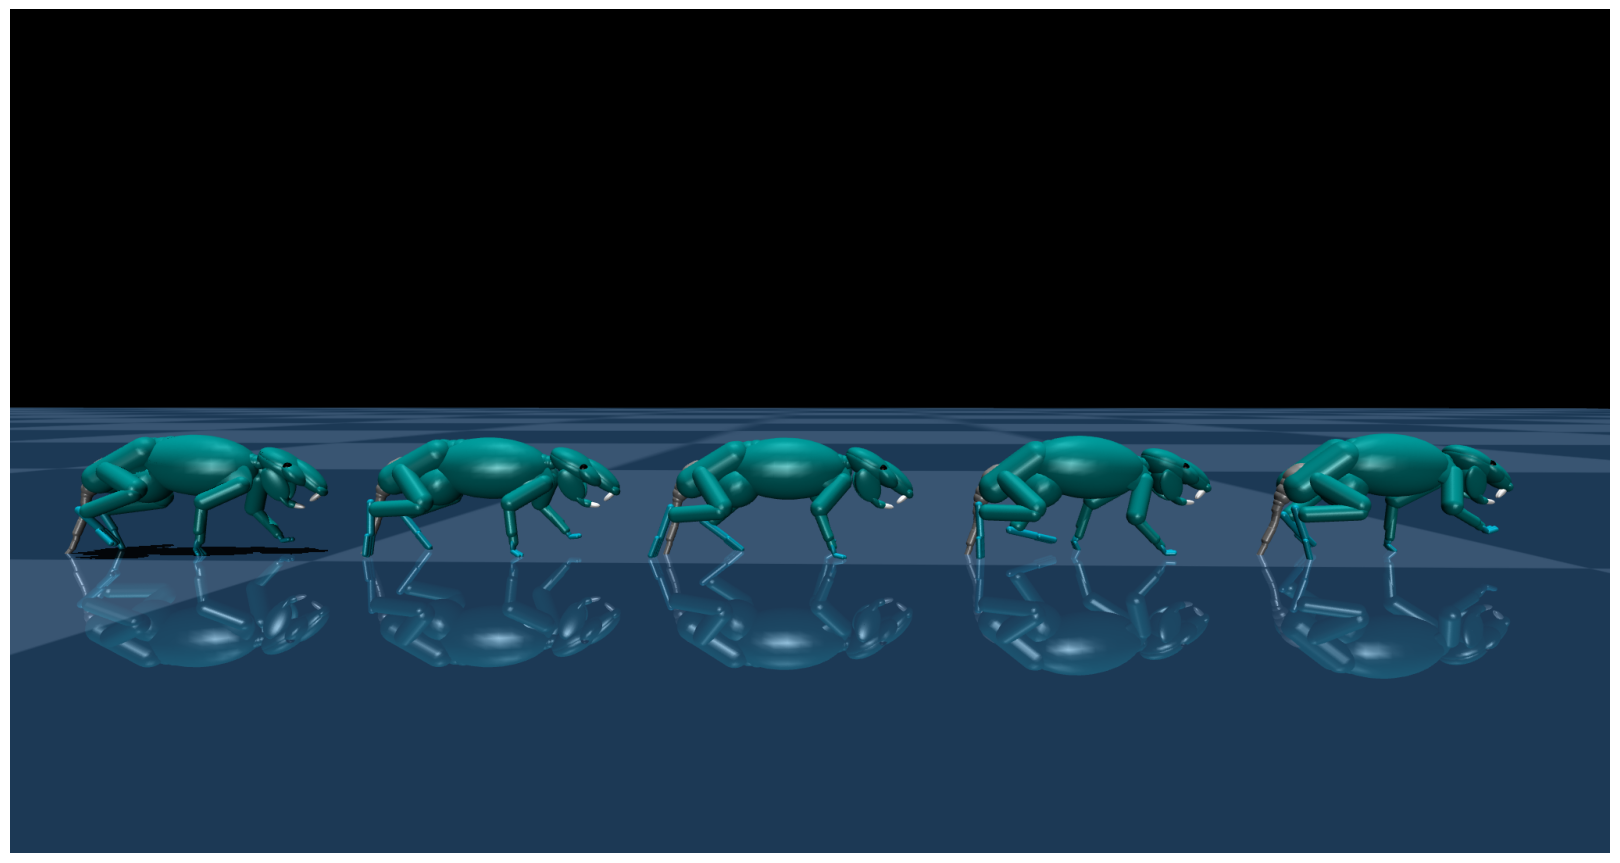

In [20]:
# High-res render for Trot
assert captured_cam_trot, "Click 'Capture Camera' above first"

hires_cam = mujoco.MjvCamera()
hires_cam.type = mujoco.mjtCamera.mjCAMERA_FREE
hires_cam.azimuth = captured_cam_trot["azimuth"]
hires_cam.elevation = captured_cam_trot["elevation"]
hires_cam.distance = captured_cam_trot["distance"]
hires_cam.lookat[:] = captured_cam_trot["lookat"]

hires_renderer = mujoco.Renderer(trail_model, height=TRAIL_RENDER_HEIGHT, width=TRAIL_RENDER_WIDTH)
hires_renderer.update_scene(trail_data, camera=hires_cam)
hires_frame = hires_renderer.render().copy()
hires_renderer.close()

save_name = f"trail_trot_{gd['name']}"

fig, ax = plt.subplots(figsize=(16, 9))
ax.imshow(hires_frame)
ax.axis("off")
fig.subplots_adjust(left=0, right=1, top=1, bottom=0)

gait_output = OUTPUT_DIR / "trot"
gait_output.mkdir(parents=True, exist_ok=True)
for ext in ["pdf", "svg", "png"]:
    fig.savefig(gait_output / f"{save_name}.{ext}", bbox_inches="tight", pad_inches=0, dpi=300)
print(f"Saved to {gait_output / save_name}.[pdf|svg|png]")
plt.show()


## Canter — Interactive Trail Render

In [27]:
# Build multi-rodent trail for Canter
# === Per-gait overrides (edit these) ===
TRAIL_T_START_CANTER = TRAIL_T_START       # override start timestep
TRAIL_T_END_CANTER = TRAIL_T_END           # override end timestep
TRAIL_NUM_FRAMES_CANTER = TRAIL_NUM_FRAMES # override number of poses
TRAIL_TIMESTEPS_CANTER = [160, 200, 240, 280, 320]                 # explicit timesteps; empty = linspace

gd = gait_data["Canter"]
qpos = gd["qpos"]
model = gd["model"]
data = gd["data"]
walker_xml = gd["walker_xml"]
arena_xml = gd["arena_xml"]

# Trail timesteps
if TRAIL_TIMESTEPS_CANTER:
    trail_indices = np.array(TRAIL_TIMESTEPS_CANTER, dtype=int)
else:
    trail_indices = np.linspace(TRAIL_T_START_CANTER, TRAIL_T_END_CANTER, TRAIL_NUM_FRAMES_CANTER, dtype=int)
trail_num_frames = len(trail_indices)

# Build multi-rodent MjSpec
trail_spec = mujoco.MjSpec.from_file(arena_xml)
for i in range(trail_num_frames):
    rodent_spec_i = mujoco.MjSpec.from_file(walker_xml)
    frame_i = trail_spec.worldbody.add_frame(pos=(0, 0, 0), quat=(1, 0, 0, 0))
    body_i = frame_i.attach_body(rodent_spec_i.body("walker"), "", suffix=f"-t{i}")
    body_i.add_freejoint(name=f"root-t{i}")

# Camera
cam_pos = np.array(TRAIL_CAM_POS, dtype=float)
cam_lookat = np.array(TRAIL_CAM_LOOKAT, dtype=float)
look_dir = cam_lookat - cam_pos
cam_z = -look_dir / np.linalg.norm(look_dir)
world_up = np.array([0.0, 0.0, 1.0])
cam_x = np.cross(world_up, cam_z)
cam_x /= np.linalg.norm(cam_x)
cam_y = np.cross(cam_z, cam_x)
R = np.column_stack([cam_x, cam_y, cam_z])
trace = R[0, 0] + R[1, 1] + R[2, 2]
s = 2.0 * np.sqrt(1.0 + trace)
cam_quat = [0.25 * s, (R[2, 1] - R[1, 2]) / s, (R[0, 2] - R[2, 0]) / s, (R[1, 0] - R[0, 1]) / s]

overview_cam = trail_spec.worldbody.add_camera(name="trail_overview")
overview_cam.pos = cam_pos.tolist()
overview_cam.quat = cam_quat
overview_cam.fovy = TRAIL_CAM_FOVY

overhead = trail_spec.worldbody.add_light(name="overhead")
overhead.pos = [0.0, 0.0, 10.0]
overhead.dir = [0, 0, -1]
overhead.type = mujoco.mjtLightType.mjLIGHT_DIRECTIONAL
overhead.diffuse = [1.0, 1.0, 1.0]
overhead.specular = [0.3, 0.3, 0.3]

trail_model = trail_spec.compile()

# Disable tracking lights from rodent copies
for i in range(trail_model.nlight):
    lname = mujoco.mj_id2name(trail_model, mujoco.mjtObj.mjOBJ_LIGHT, i)
    if lname and "tracking_light" in lname:
        trail_model.light_diffuse[i] = [0, 0, 0]
        trail_model.light_specular[i] = [0, 0, 0]

trail_data = mujoco.MjData(trail_model)

# Set each copy's qpos
nq_single = model.nq
for i, t in enumerate(trail_indices):
    start = i * nq_single
    trail_data.qpos[start : start + nq_single] = qpos[t]
mujoco.mj_forward(trail_model, trail_data)

print(f"{trail_num_frames} poses at timesteps: {trail_indices.tolist()}")

# Interactive viewer
interactive_height = 720
interactive_width = 1280

interactive_renderer = mujoco.Renderer(trail_model, height=interactive_height, width=interactive_width)
free_cam = mujoco.MjvCamera()
free_cam.type = mujoco.mjtCamera.mjCAMERA_FREE

try:
    _has_capture = bool(captured_cam_canter)
except NameError:
    captured_cam_canter = {}
    _has_capture = False

if _has_capture:
    free_cam.azimuth = captured_cam_canter["azimuth"]
    free_cam.elevation = captured_cam_canter["elevation"]
    free_cam.distance = captured_cam_canter["distance"]
    free_cam.lookat[:] = captured_cam_canter["lookat"]
else:
    free_cam.lookat[:] = TRAIL_CAM_LOOKAT
    free_cam.distance = float(np.linalg.norm(np.array(TRAIL_CAM_POS) - np.array(TRAIL_CAM_LOOKAT)))
    _offset = np.array(TRAIL_CAM_POS) - np.array(TRAIL_CAM_LOOKAT)
    free_cam.azimuth = float(np.degrees(np.arctan2(_offset[1], _offset[0])))
    free_cam.elevation = float(np.degrees(np.arcsin(_offset[2] / np.linalg.norm(_offset))))

img_widget = widgets.Image(format="jpeg", layout=widgets.Layout(width=f"{interactive_width}px"))

def render_view(change=None):
    interactive_renderer.update_scene(trail_data, camera=free_cam)
    frame = interactive_renderer.render()
    buf = io.BytesIO()
    PIL.Image.fromarray(frame).save(buf, format="JPEG", quality=90)
    img_widget.value = buf.getvalue()

azimuth_slider = widgets.FloatSlider(value=free_cam.azimuth, min=-180, max=180, step=1, description="Azimuth", continuous_update=True, layout=widgets.Layout(width="500px"))
elevation_slider = widgets.FloatSlider(value=free_cam.elevation, min=-90, max=90, step=1, description="Elevation", continuous_update=True, layout=widgets.Layout(width="500px"))
distance_slider = widgets.FloatSlider(value=free_cam.distance, min=0.1, max=5.0, step=0.05, description="Distance", continuous_update=True, layout=widgets.Layout(width="500px"))
lookat_x = widgets.FloatSlider(value=free_cam.lookat[0], min=-3, max=3, step=0.05, description="Lookat X", continuous_update=True, layout=widgets.Layout(width="500px"))
lookat_y = widgets.FloatSlider(value=free_cam.lookat[1], min=-3, max=3, step=0.05, description="Lookat Y", continuous_update=True, layout=widgets.Layout(width="500px"))
lookat_z = widgets.FloatSlider(value=free_cam.lookat[2], min=-1, max=2, step=0.05, description="Lookat Z", continuous_update=True, layout=widgets.Layout(width="500px"))

def on_slider_change(change):
    free_cam.azimuth = azimuth_slider.value
    free_cam.elevation = elevation_slider.value
    free_cam.distance = distance_slider.value
    free_cam.lookat[:] = [lookat_x.value, lookat_y.value, lookat_z.value]
    render_view()

for sl in [azimuth_slider, elevation_slider, distance_slider, lookat_x, lookat_y, lookat_z]:
    sl.observe(on_slider_change, names="value")

capture_label = widgets.Label(value="")
capture_btn = widgets.Button(description="Capture Camera", button_style="success")

def on_capture(btn):
    captured_cam_canter["azimuth"] = azimuth_slider.value
    captured_cam_canter["elevation"] = elevation_slider.value
    captured_cam_canter["distance"] = distance_slider.value
    captured_cam_canter["lookat"] = [lookat_x.value, lookat_y.value, lookat_z.value]
    capture_label.value = f"Captured: az={captured_cam_canter['azimuth']:.1f} el={captured_cam_canter['elevation']:.1f} dist={captured_cam_canter['distance']:.2f}"

capture_btn.on_click(on_capture)
render_view()

controls = widgets.VBox([
    widgets.HBox([azimuth_slider, elevation_slider]),
    widgets.HBox([distance_slider]),
    widgets.HBox([lookat_x, lookat_y, lookat_z]),
    widgets.HBox([capture_btn, capture_label]),
])
ipy_display(widgets.VBox([img_widget, controls]))


5 poses at timesteps: [160, 200, 240, 280, 320]


Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/maintain_velocity_trails/canter/trail_canter_SCAMPER_S7e-1.[pdf|svg|png]


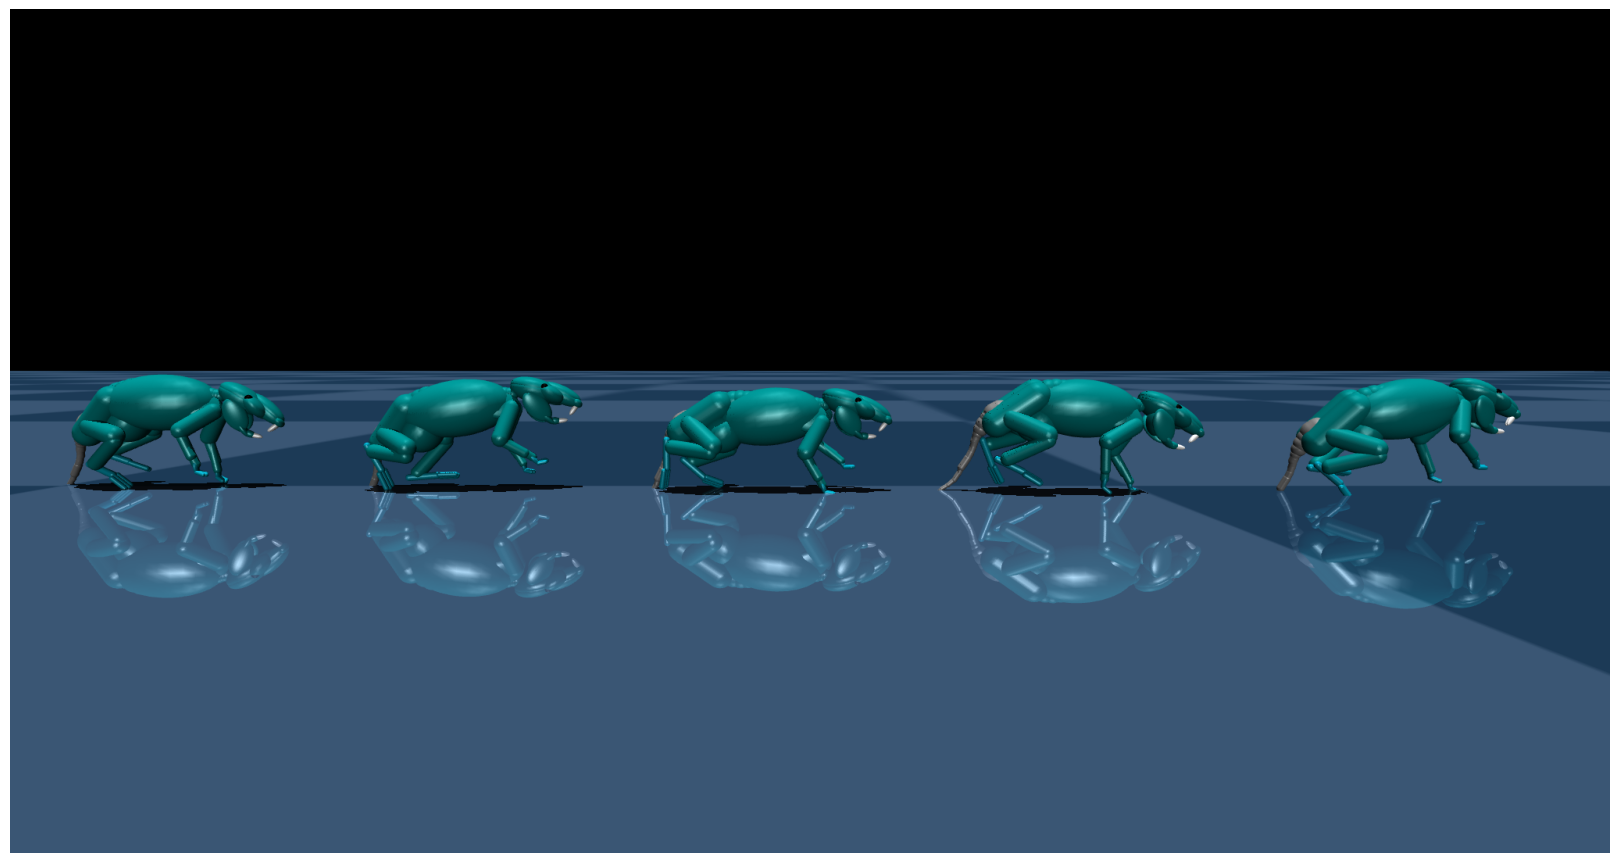

In [29]:
# High-res render for Canter
assert captured_cam_canter, "Click 'Capture Camera' above first"

hires_cam = mujoco.MjvCamera()
hires_cam.type = mujoco.mjtCamera.mjCAMERA_FREE
hires_cam.azimuth = captured_cam_canter["azimuth"]
hires_cam.elevation = captured_cam_canter["elevation"]
hires_cam.distance = captured_cam_canter["distance"]
hires_cam.lookat[:] = captured_cam_canter["lookat"]

hires_renderer = mujoco.Renderer(trail_model, height=TRAIL_RENDER_HEIGHT, width=TRAIL_RENDER_WIDTH)
hires_renderer.update_scene(trail_data, camera=hires_cam)
hires_frame = hires_renderer.render().copy()
hires_renderer.close()

save_name = f"trail_canter_{gd['name']}"

fig, ax = plt.subplots(figsize=(16, 9))
ax.imshow(hires_frame)
ax.axis("off")
fig.subplots_adjust(left=0, right=1, top=1, bottom=0)

gait_output = OUTPUT_DIR / "canter"
gait_output.mkdir(parents=True, exist_ok=True)
for ext in ["pdf", "svg", "png"]:
    fig.savefig(gait_output / f"{save_name}.{ext}", bbox_inches="tight", pad_inches=0, dpi=300)
print(f"Saved to {gait_output / save_name}.[pdf|svg|png]")
plt.show()
